In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from scipy.ndimage import rotate, gaussian_filter
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split

### SETUP

##### cifar load 50 image/class

In [2]:
# load cifar10
(all_images, all_labels), (clean_test_images, clean_test_labels) = cifar10.load_data()
all_labels = all_labels.flatten()
clean_test_labels = clean_test_labels.flatten()


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2559s 15us/step


In [4]:
# pick 50 images from each of the 10 classes
np.random.seed(42)
picked = []
for class_number in range(10):
    spots = np.where(all_labels == class_number)[0]
    chosen = np.random.choice(spots, 50, replace=False)
    picked.extend(chosen)

small_images = all_images[picked]
small_labels = all_labels[picked]


In [5]:
# split the 500 into 400 train and 100 val
train_images, val_images, train_labels, val_labels = train_test_split(
    small_images, small_labels, test_size=100, stratify=small_labels, random_state=42)


In [6]:
# make pixels go from 0 to 1
train_images = train_images / 255.0
val_images = val_images / 255.0

print(train_images.shape, val_images.shape)
print(np.bincount(train_labels))
print(np.bincount(val_labels))

(400, 32, 32, 3) (100, 32, 32, 3)
[40 40 40 40 40 40 40 40 40 40]
[10 10 10 10 10 10 10 10 10 10]


##### inception module

In [7]:


def inception_block(x, n1, n3_small, n3, n5_small, n5, n_pool):
    # branch 1: just a 1x1 conv
    branch1 = layers.Conv2D(n1, 1, padding='same', activation='relu')(x)

    # branch 2: 1x1 to shrink channels, then 3x3
    branch2 = layers.Conv2D(n3_small, 1, padding='same', activation='relu')(x)
    branch2 = layers.Conv2D(n3, 3, padding='same', activation='relu')(branch2)

    # branch 3: 1x1 to shrink channels, then 5x5
    branch3 = layers.Conv2D(n5_small, 1, padding='same', activation='relu')(x)
    branch3 = layers.Conv2D(n5, 5, padding='same', activation='relu')(branch3)

    # branch 4: max pool, then 1x1
    branch4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    branch4 = layers.Conv2D(n_pool, 1, padding='same', activation='relu')(branch4)

    # glue all 4 branches together
    return layers.Concatenate()([branch1, branch2, branch3, branch4])

##### Building the model

In [8]:
def make_model(dropout_rate=0.0):
    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
    x = layers.MaxPooling2D(2)(x)

    x = inception_block(x, 16, 16, 24, 8, 8, 8)
    x = layers.MaxPooling2D(2)(x)

    x = inception_block(x, 32, 32, 48, 16, 16, 16)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    return models.Model(inputs, outputs)

model = make_model()
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()
print("total params:", model.count_params())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 32)        │             896 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 16, 16, 32)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 16, 16, 8)         │             264 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 16, 16, 32)        │               0 │ max_pooling2d[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 24)        │           3,480 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 8)         │           1,608 │ conv2d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 16, 16, 8)         │             264 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 16, 16, 56)        │               0 │ conv2d_1[0][0],            │
│                               │                           │                 │ conv2d_3[0][0],            │
│                               │                           │                 │ conv2d_5[0][0],            │
│                               │                           │                 │ conv2d_6[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 8, 8, 56)          │               0 │ concatenate[0][0]          │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 8, 8, 32)          │           1,824 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 8, 8, 16)          │             912 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_3               │ (None, 8, 8, 56)          │               

 Total params: 34,458 (134.60 KB)

 Trainable params: 34,458 (134.60 KB)

 Non-trainable params: 0 (0.00 B)

total params: 34458


##### Shifted cases

In [9]:


np.random.seed(123)

def make_shifted(images):
    new_images = []
    for img in images:
        img = img.astype('float32')

        # rotate up to 25 degrees either way
        angle = np.random.uniform(-25, 25)
        img = rotate(img, angle, axes=(0, 1), reshape=False, mode='nearest')

        # brightness and contrast
        contrast = np.random.uniform(0.5, 1.5)
        brightness = np.random.uniform(-50, 50)
        img = img * contrast + brightness

        # blur half the time
        if np.random.rand() < 0.5:
            img = gaussian_filter(img, sigma=(1, 1, 0))

        # noise half the time
        if np.random.rand() < 0.5:
            img = img + np.random.normal(0, 20, img.shape)

        # block out a 16x16 square (25% of the image)
        row = np.random.randint(0, 17)
        col = np.random.randint(0, 17)
        img[row:row+16, col:col+16, :] = 0

        # my guess for the hidden one: grayscale or swap channels
        pick = np.random.rand()
        if pick < 0.25:
            gray = img.mean(axis=2, keepdims=True)
            img = np.repeat(gray, 3, axis=2)
        elif pick < 0.5:
            img = img[:, :, ::-1]

        new_images.append(np.clip(img, 0, 255))
    return np.array(new_images) / 255.0

# clean_test_images must still be 0 to 255 here
shifted_test_images = make_shifted(clean_test_images)
shifted_test_labels = clean_test_labels

# save so you never have to redo it
np.save('shifted_test_images.npy', shifted_test_images)
np.save('shifted_test_labels.npy', shifted_test_labels)

# now scale the clean test to 0 to 1
clean_test_images = clean_test_images / 255.0

print(shifted_test_images.shape, clean_test_images.shape)

(10000, 32, 32, 3) (10000, 32, 32, 3)


### PART A

In [10]:
def train_baseline(seed):
    tf.keras.utils.set_random_seed(seed)
    model = make_model(dropout_rate=0.0)
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(train_images, train_labels,
                        validation_data=(val_images, val_labels),
                        epochs=60, batch_size=32, verbose=0)

    train_acc = history.history['accuracy'][-1]
    val_acc = history.history['val_accuracy'][-1]
    clean_acc = model.evaluate(clean_test_images, clean_test_labels, verbose=0)[1]
    shifted_acc = model.evaluate(shifted_test_images, shifted_test_labels, verbose=0)[1]
    return history, train_acc, val_acc, clean_acc, shifted_acc

In [11]:
all_histories = []
train_accs, val_accs, clean_accs, shifted_accs = [], [], [], []

for seed in [1, 2, 3]:
    h, a, b, c, d = train_baseline(seed)
    all_histories.append(h)
    train_accs.append(a)
    val_accs.append(b)
    clean_accs.append(c)
    shifted_accs.append(d)
    print("seed", seed, "done")

print("train   :", np.mean(train_accs), "+-", np.std(train_accs))
print("val     :", np.mean(val_accs), "+-", np.std(val_accs))
print("clean   :", np.mean(clean_accs), "+-", np.std(clean_accs))
print("shifted :", np.mean(shifted_accs), "+-", np.std(shifted_accs))

seed 1 done
seed 2 done
seed 3 done
train   : 0.5025000075499216 +- 0.023540759294183065
val     : 0.326666663090388 +- 0.03858612311228215
clean   : 0.336899995803833 +- 0.013893171155770294
shifted : 0.1536333312590917 +- 0.00856050339481052


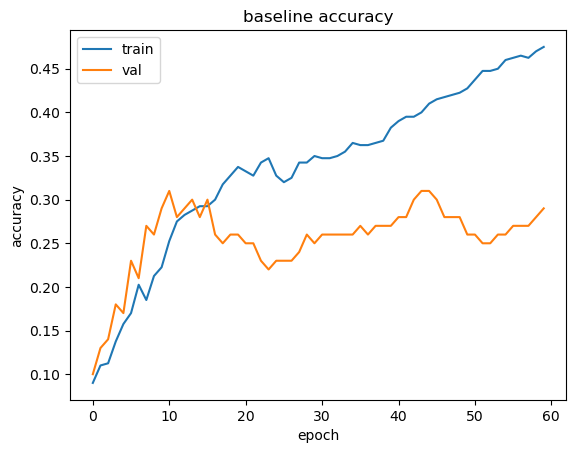

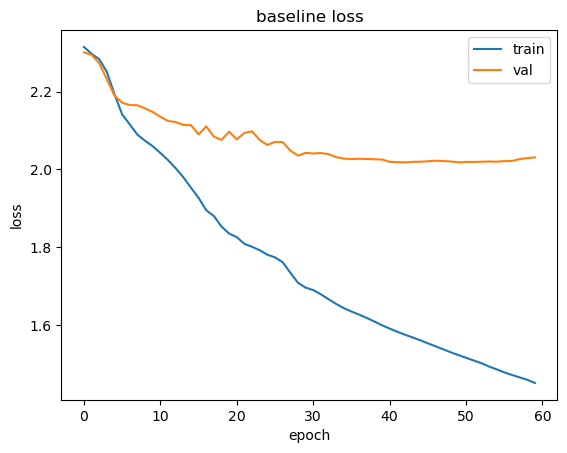

In [12]:
# learning curves
h = all_histories[0]
plt.plot(h.history['accuracy'], label='train')
plt.plot(h.history['val_accuracy'], label='val')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.title('baseline accuracy')
plt.show()

plt.plot(h.history['loss'], label='train')
plt.plot(h.history['val_loss'], label='val')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.title('baseline loss')
plt.show()

the model got 34% on clean test but only 15% on shifted test so it drops a lot when the images are rotated dark blurry noisy or blocked. thats covariate shift because the test pictures look different from what it trained on. its also overfitting because train acc was 50% while val was only 33% so it memorized some of the 400 images instead of learning real patterns. so its both. overfitting from having so little data and covariate shift from the corrupted test set. the shifted score is close to random guessing which is 10% since it never saw anything rotated or dark or covered in training

### PART D

In [16]:
######### model with batch norm

def conv_block(x, filters, size, use_bn):
    x = layers.Conv2D(filters, size, padding='same', use_bias=not use_bn)(x)
    if use_bn:
        x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def inception_block_v2(x, n1, n3_small, n3, n5_small, n5, n_pool, use_bn):
    b1 = conv_block(x, n1, 1, use_bn)

    b2 = conv_block(x, n3_small, 1, use_bn)
    b2 = conv_block(b2, n3, 3, use_bn)

    b3 = conv_block(x, n5_small, 1, use_bn)
    b3 = conv_block(b3, n5, 5, use_bn)

    b4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    b4 = conv_block(b4, n_pool, 1, use_bn)

    return layers.Concatenate()([b1, b2, b3, b4])

def make_model_v2(dropout_rate=0.0, use_bn=False):
    inputs = layers.Input(shape=(32, 32, 3))
    x = conv_block(inputs, 32, 3, use_bn)
    x = layers.MaxPooling2D(2)(x)
    x = inception_block_v2(x, 16, 16, 24, 8, 8, 8, use_bn)
    x = layers.MaxPooling2D(2)(x)
    x = inception_block_v2(x, 32, 32, 48, 16, 16, 16, use_bn)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    return models.Model(inputs, outputs)

print(make_model_v2(0.3, True).count_params())

35274


In [17]:
########## Augmentations all random every epoch

flip_layer = layers.RandomFlip('horizontal')
rotate_layer = layers.RandomRotation(30 / 360, fill_mode='nearest')   # about +-30 degrees
shift_layer = layers.RandomTranslation(0.125, 0.125, fill_mode='nearest')  # about 4 pixels

def photo_aug(images):
    n = tf.shape(images)[0]

    # brightness and contrast
    contrast = tf.random.uniform([n, 1, 1, 1], 0.6, 1.4)
    bright = tf.random.uniform([n, 1, 1, 1], -0.2, 0.2)
    images = images * contrast + bright

    # saturation
    gray = tf.reduce_mean(images, axis=-1, keepdims=True)
    sat = tf.random.uniform([n, 1, 1, 1], 0.5, 1.5)
    images = gray + sat * (images - gray)

    # blur on 30% of images
    blurred = tf.nn.avg_pool2d(images, 3, 1, 'SAME')
    use_blur = tf.random.uniform([n, 1, 1, 1]) < 0.3
    images = tf.where(use_blur, blurred, images)

    # noise on 30% of images
    noisy = images + tf.random.normal(tf.shape(images), stddev=0.05)
    use_noise = tf.random.uniform([n, 1, 1, 1]) < 0.3
    images = tf.where(use_noise, noisy, images)

    # grayscale on 15% of images
    gray_full = tf.tile(tf.reduce_mean(images, axis=-1, keepdims=True), [1, 1, 1, 3])
    use_gray = tf.random.uniform([n, 1, 1, 1]) < 0.15
    images = tf.where(use_gray, gray_full, images)

    return tf.clip_by_value(images, 0.0, 1.0)

def cutout(images):
    n = tf.shape(images)[0]
    size = tf.random.uniform([n, 1, 1], 8, 17, dtype=tf.int32)
    top = tf.random.uniform([n, 1, 1], 0, 25, dtype=tf.int32)
    left = tf.random.uniform([n, 1, 1], 0, 25, dtype=tf.int32)
    rows = tf.range(32)[None, :, None]
    cols = tf.range(32)[None, None, :]
    box = (rows >= top) & (rows < top + size) & (cols >= left) & (cols < left + size)
    use = tf.random.uniform([n, 1, 1]) < 0.5      # only half the images get a box
    box = tf.cast(box & use, tf.float32)[..., None]
    return images * (1.0 - box)

def mixup(images, labels):
    lam = tf.random.uniform([], 0.5, 1.0)
    order = tf.random.shuffle(tf.range(tf.shape(images)[0]))
    images = lam * images + (1 - lam) * tf.gather(images, order)
    labels = lam * labels + (1 - lam) * tf.gather(labels, order)
    return images, labels

def make_augment(cfg):
    def augment(images, labels):
        if cfg['geo']:
            images = flip_layer(images, training=True)
            images = rotate_layer(images, training=True)
            images = shift_layer(images, training=True)
        if cfg['photo']:
            images = photo_aug(images)
        if cfg['cutout']:
            images = cutout(images)
        if cfg['mixup']:
            images, labels = mixup(images, labels)
        return images, labels
    return augment

In [18]:
########### one run for one config and one seed

train_labels_onehot = tf.keras.utils.to_categorical(train_labels, 10)
val_labels_onehot = tf.keras.utils.to_categorical(val_labels, 10)
clean_labels_onehot = tf.keras.utils.to_categorical(clean_test_labels, 10)
shifted_labels_onehot = tf.keras.utils.to_categorical(shifted_test_labels, 10)

def run_config(cfg, seed):
    tf.keras.utils.set_random_seed(seed)

    if cfg['final']:
        model = make_model_v2(dropout_rate=0.3, use_bn=True)
        lr = tf.keras.optimizers.schedules.CosineDecay(0.003, 60 * 13)
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
        callbacks = [tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True)]
    else:
        model = make_model_v2(dropout_rate=0.0, use_bn=False)
        optimizer = tf.keras.optimizers.Adam()
        callbacks = []

    smoothing = 0.1 if cfg['mixup'] else 0.0
    model.compile(optimizer=optimizer,
                  loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=smoothing),
                  metrics=[tf.keras.metrics.CategoricalAccuracy(name='accuracy')])

    data = tf.data.Dataset.from_tensor_slices(
        (train_images.astype('float32'), train_labels_onehot))
    data = data.shuffle(400).batch(32).map(make_augment(cfg))

    model.fit(data, validation_data=(val_images, val_labels_onehot),
              epochs=60, verbose=0, callbacks=callbacks)

    val_acc = model.evaluate(val_images, val_labels_onehot, verbose=0)[1]
    clean_acc = model.evaluate(clean_test_images, clean_labels_onehot, verbose=0)[1]
    shifted_acc = model.evaluate(shifted_test_images, shifted_labels_onehot, verbose=0)[1]
    return val_acc, clean_acc, shifted_acc

In [19]:
######## all 7 rows, 3 seeds each

configs = {
    'No augmentation':          dict(geo=False, photo=False, cutout=False, mixup=False, final=False),
    'Geometric only':           dict(geo=True,  photo=False, cutout=False, mixup=False, final=False),
    'Photometric only':         dict(geo=False, photo=True,  cutout=False, mixup=False, final=False),
    'Geometric + photometric':  dict(geo=True,  photo=True,  cutout=False, mixup=False, final=False),
    '+ Cutout':                 dict(geo=True,  photo=True,  cutout=True,  mixup=False, final=False),
    '+ Mixup + label smoothing':dict(geo=True,  photo=True,  cutout=True,  mixup=True,  final=False),
    'Final model':              dict(geo=True,  photo=True,  cutout=True,  mixup=True,  final=True),
}

table = {}
for name, cfg in configs.items():
    v, c, s = [], [], []
    for seed in [1, 2, 3]:
        a, b, d = run_config(cfg, seed)
        v.append(a)
        c.append(b)
        s.append(d)
    table[name] = (v, c, s)
    print(name)
    print("  val    :", round(np.mean(v) * 100, 1), "+-", round(np.std(v) * 100, 1))
    print("  clean  :", round(np.mean(c) * 100, 1), "+-", round(np.std(c) * 100, 1))
    print("  shifted:", round(np.mean(s) * 100, 1), "+-", round(np.std(s) * 100, 1))

C:\Users\mbinm\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


No augmentation
  val    : 29.0 +- 5.0
  clean  : 32.1 +- 1.2
  shifted: 14.2 +- 0.7
Geometric only
  val    : 31.3 +- 5.2
  clean  : 31.1 +- 3.1
  shifted: 13.5 +- 0.8
Photometric only
  val    : 29.0 +- 1.4
  clean  : 33.2 +- 0.6
  shifted: 18.2 +- 0.6
Geometric + photometric
  val    : 28.3 +- 4.8
  clean  : 29.7 +- 1.7
  shifted: 17.3 +- 1.7
+ Cutout
  val    : 24.7 +- 2.5
  clean  : 28.6 +- 1.5
  shifted: 17.7 +- 0.9


TypeError: in user code:

    File "C:\Users\mbinm\AppData\Local\Temp\ipykernel_36748\1275388155.py", line 67, in augment  *
        images, labels = mixup(images, labels)
    File "C:\Users\mbinm\AppData\Local\Temp\ipykernel_36748\1275388155.py", line 53, in mixup  *
        labels = lam * labels + (1 - lam) * tf.gather(labels, order)

    TypeError: Input 'y' of 'Mul' Op has type float64 that does not match type float32 of argument 'x'.


In [21]:
def mixup(images, labels):
    labels = tf.cast(labels, tf.float32)
    lam = tf.random.uniform([], 0.5, 1.0)
    order = tf.random.shuffle(tf.range(tf.shape(images)[0]))
    images = lam * images + (1 - lam) * tf.gather(images, order)
    labels = lam * labels + (1 - lam) * tf.gather(labels, order)
    return images, labels

for name in ['+ Mixup + label smoothing', 'Final model']:
    cfg = configs[name]
    v, c, s = [], [], []
    for seed in [1, 2, 3]:
        a, b, d = run_config(cfg, seed)
        v.append(a)
        c.append(b)
        s.append(d)
    table[name] = (v, c, s)
    print(name)
    print("  val    :", round(np.mean(v) * 100, 1), "+-", round(np.std(v) * 100, 1))
    print("  clean  :", round(np.mean(c) * 100, 1), "+-", round(np.std(c) * 100, 1))
    print("  shifted:", round(np.mean(s) * 100, 1), "+-", round(np.std(s) * 100, 1))

+ Mixup + label smoothing
  val    : 23.7 +- 3.8
  clean  : 26.4 +- 2.3
  shifted: 17.9 +- 0.5
Final model
  val    : 28.0 +- 9.9
  clean  : 31.0 +- 10.5
  shifted: 20.1 +- 5.6


In [22]:
print(table['Final model'])

([0.3499999940395355, 0.14000000059604645, 0.3499999940395355], [0.38199999928474426, 0.16200000047683716, 0.3862999975681305], [0.24570000171661377, 0.12219999730587006, 0.23589999973773956])


### PART E

In [24]:
def run_config(cfg, seed, return_model=False):
    tf.keras.utils.set_random_seed(seed)

    if cfg['final']:
        model = make_model_v2(dropout_rate=0.3, use_bn=True)
        lr = tf.keras.optimizers.schedules.CosineDecay(0.003, 60 * 13)
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
        callbacks = [tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10, restore_best_weights=True)]
    else:
        model = make_model_v2(dropout_rate=0.0, use_bn=False)
        optimizer = tf.keras.optimizers.Adam()
        callbacks = []

    smoothing = 0.1 if cfg['mixup'] else 0.0
    model.compile(optimizer=optimizer,
                  loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=smoothing),
                  metrics=[tf.keras.metrics.CategoricalAccuracy(name='accuracy')])

    data = tf.data.Dataset.from_tensor_slices(
        (train_images.astype('float32'), train_labels_onehot))
    data = data.shuffle(400).batch(32).map(make_augment(cfg))

    model.fit(data, validation_data=(val_images, val_labels_onehot),
              epochs=60, verbose=0, callbacks=callbacks)

    # if we only want the trained model (for part E), give it back
    if return_model:
        return model

    val_acc = model.evaluate(val_images, val_labels_onehot, verbose=0)[1]
    clean_acc = model.evaluate(clean_test_images, clean_labels_onehot, verbose=0)[1]
    shifted_acc = model.evaluate(shifted_test_images, shifted_labels_onehot, verbose=0)[1]
    return val_acc, clean_acc, shifted_acc

In [25]:
best_model = None
best_val = -1

for seed in [1, 2, 3]:
    m = run_config(configs['Final model'], seed, return_model=True)
    v = m.evaluate(val_images, val_labels_onehot, verbose=0)[1]
    print("seed", seed, "val acc", v)
    if v > best_val:
        best_val = v
        best_model = m

seed 1 val acc 0.33000001311302185
seed 2 val acc 0.3499999940395355
seed 3 val acc 0.36000001430511475


airplane 18.7
car 18.0
bird 40.3
cat 30.9
deer 15.4
dog 15.4
frog 19.0
horse 10.5
ship 18.0
truck 38.0


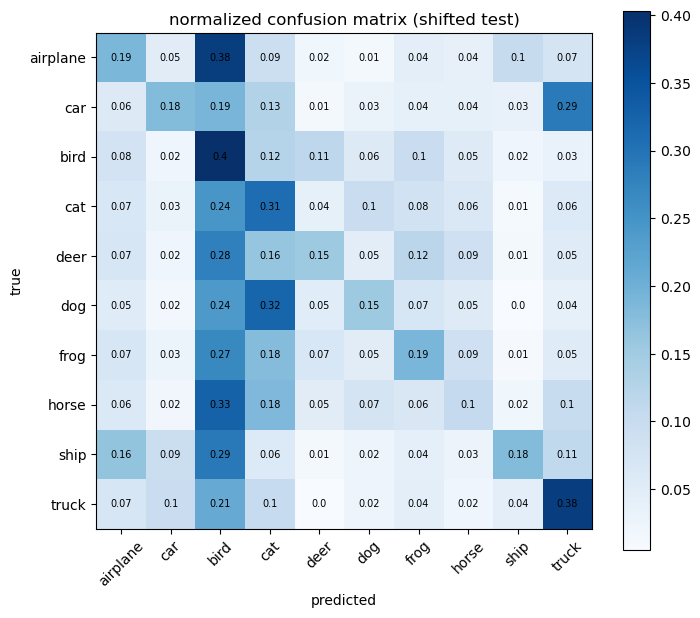

In [26]:
from sklearn.metrics import confusion_matrix

class_names = ['airplane','car','bird','cat','deer','dog','frog','horse','ship','truck']

shifted_probs = best_model.predict(shifted_test_images, verbose=0)
shifted_pred = np.argmax(shifted_probs, axis=1)

matrix = confusion_matrix(shifted_test_labels, shifted_pred)
matrix_norm = matrix / matrix.sum(axis=1, keepdims=True)

for i in range(10):
    print(class_names[i], round(matrix_norm[i, i] * 100, 1))

plt.figure(figsize=(8, 7))
plt.imshow(matrix_norm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.title('normalized confusion matrix (shifted test)')
for i in range(10):
    for j in range(10):
        color = 'white' if matrix_norm[i, j] > 0.5 else 'black'
        plt.text(j, i, round(matrix_norm[i, j], 2), ha='center', va='center', fontsize=7, color=color)
plt.show()

In [27]:
off = matrix_norm.copy()
np.fill_diagonal(off, 0)

for k in range(5):
    i, j = np.unravel_index(np.argmax(off), off.shape)
    print(class_names[i], "predicted as", class_names[j], round(off[i, j] * 100, 1), "%")
    off[i, j] = 0

airplane predicted as bird 38.2 %
horse predicted as bird 32.6 %
dog predicted as cat 32.1 %
ship predicted as bird 29.0 %
car predicted as truck 28.9 %


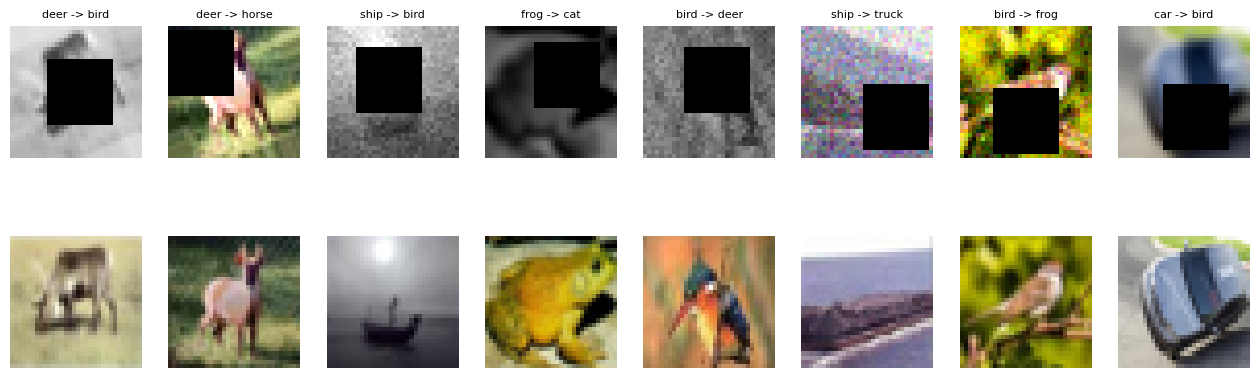

In [28]:
wrong = np.where(shifted_pred != shifted_test_labels)[0]
np.random.seed(0)
show = np.random.choice(wrong, 8, replace=False)

plt.figure(figsize=(16, 5))
for n, idx in enumerate(show):
    plt.subplot(2, 8, n + 1)
    plt.imshow(shifted_test_images[idx])
    plt.title(class_names[shifted_test_labels[idx]] + " -> " + class_names[shifted_pred[idx]], fontsize=8)
    plt.axis('off')
    plt.subplot(2, 8, n + 9)
    plt.imshow(clean_test_images[idx])
    plt.axis('off')
plt.show()

In [29]:
clean_labels_onehot = tf.keras.utils.to_categorical(clean_test_labels, 10)

gray_images = np.repeat(clean_test_images.mean(axis=3, keepdims=True), 3, axis=3)
swap_images = clean_test_images[:, :, :, ::-1]

clean_acc = best_model.evaluate(clean_test_images, clean_labels_onehot, verbose=0)[1]
gray_acc = best_model.evaluate(gray_images, clean_labels_onehot, verbose=0)[1]
swap_acc = best_model.evaluate(swap_images, clean_labels_onehot, verbose=0)[1]

print("clean           :", round(clean_acc * 100, 1))
print("grayscale only  :", round(gray_acc * 100, 1))
print("channel swap    :", round(swap_acc * 100, 1))

# compare with the model that had no augmentation
plain_model = run_config(configs['No augmentation'], 1, return_model=True)
print("no-aug clean    :", round(plain_model.evaluate(clean_test_images, clean_labels_onehot, verbose=0)[1] * 100, 1))
print("no-aug grayscale:", round(plain_model.evaluate(gray_images, clean_labels_onehot, verbose=0)[1] * 100, 1))
print("no-aug swap     :", round(plain_model.evaluate(swap_images, clean_labels_onehot, verbose=0)[1] * 100, 1))

clean           : 38.7
grayscale only  : 29.2
channel swap    : 23.9


C:\Users\mbinm\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


no-aug clean    : 34.1
no-aug grayscale: 26.9
no-aug swap     : 16.8
